# Model comparison

Evaluates every trained model on the **same held-out test split** and produces:
1. a comparison table (mAP50, mAP50-95, per-class AP),
2. qualitative bounding-box visualizations,
3. failure-case gallery (where models go wrong),
4. a confusion matrix per model,
5. the ablation table isolating resolution / pretraining / architecture.

Requires local checkpoints under `logs/<run_name>/`. Run the trainings first
(`python scripts/train_model.py src/config/<config>.py`). Models without a local
checkpoint are skipped automatically.

In [5]:
import sys
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision.ops import box_iou

from src.utils.evaluation import (
    find_best_checkpoint, load_model_from_config,
    build_datamodule_from_config, run_test_pass,
)
from src.utils.visualization import draw_boxes, plot_confusion_matrix
from src.models.yolov1_baseline import YoloV1Baseline

CLASS_NAMES = ["AirPlane", "Drone", "Helicopter"]

# model label -> (config path, checkpoint glob under logs/)
MODELS = {
    "YOLOv1 (128)":     ("src/config/yolov1.py",         "yolov1_baseline_*/*.ckpt"),
    "YOLOv1 (256)":     ("src/config/yolov1_256.py",     "yolov1_256_*/*.ckpt"),
    "YOLOv8n":          ("src/config/yolov8.py",         "yolov8_baseline_*/*.ckpt"),
    "YOLOv8n scratch":  ("src/config/yolov8_scratch.py", "yolov8_scratch_*/*.ckpt"),
    "YOLO26n":          ("src/config/yolo26.py",         "yolo26_baseline_*/*.ckpt"),
}

available = {}
for label, (cfg, glob) in MODELS.items():
    try:
        ckpt = find_best_checkpoint(glob)
        available[label] = (cfg, ckpt)
        print(f"{label:18s} <- {ckpt}")
    except FileNotFoundError:
        print(f"{label:18s} -- no checkpoint, skipping")

YOLOv1 (128)       <- logs/yolov1_baseline_20260612_172722/epoch=16-step=11475.ckpt
YOLOv1 (256)       <- logs/yolov1_256_20260612_174445/epoch=18-step=25650.ckpt
YOLOv8n            <- logs/yolov8_baseline_20260612_201159/epoch=21-step=29700.ckpt
YOLOv8n scratch    <- logs/yolov8_scratch_20260613_135846/epoch=27-step=37800.ckpt
YOLO26n            <- logs/yolo26_baseline_20260613_181109/epoch=26-step=36450.ckpt


## 1. Comparison table (test split)

In [6]:
rows = []
for label, (cfg, ckpt) in available.items():
    model = load_model_from_config(cfg, ckpt)
    dm = build_datamodule_from_config(cfg)
    metrics = run_test_pass(model, dm)
    rows.append({
        "model": label,
        "mAP50": metrics.get("test/mAP50"),
        "mAP50-95": metrics.get("test/mAP50-95"),
        "AP_AirPlane": metrics.get("test/AP_AirPlane"),
        "AP_Drone": metrics.get("test/AP_Drone"),
        "AP_Helicopter": metrics.get("test/AP_Helicopter"),
    })
    del model

results = pd.DataFrame(rows).set_index("model").round(4)
results

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/kuba/studia/2sem/nn/Drone-Detection/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/kuba/studia/2sem/nn/Drone-Detection/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Testing: |          | 0/? [00:00<?, ?it/s]

,mAP50,mAP50-95,AP_AirPlane,AP_Drone,AP_Helicopter
model,,,,,
YOLOv1 (128),0.5202,0.1740,0.1585,0.1196,0.2440
YOLOv1 (256),0.7262,0.2557,0.2943,0.2071,0.2658
YOLOv8n,0.9548,0.6807,0.7584,0.5341,0.7496
YOLOv8n scratch,0.9354,0.6635,0.7474,0.4951,0.7481
YOLO26n,0.9212,0.5878,0.6914,0.3690,0.7031


## 2. Qualitative bounding-box visualization

A few test images per class, with ground truth and each model's predictions side by side.
Font size and box width are auto-scaled to the image resolution, so labels are readable
regardless of whether the model runs at 128 px or 640 px.

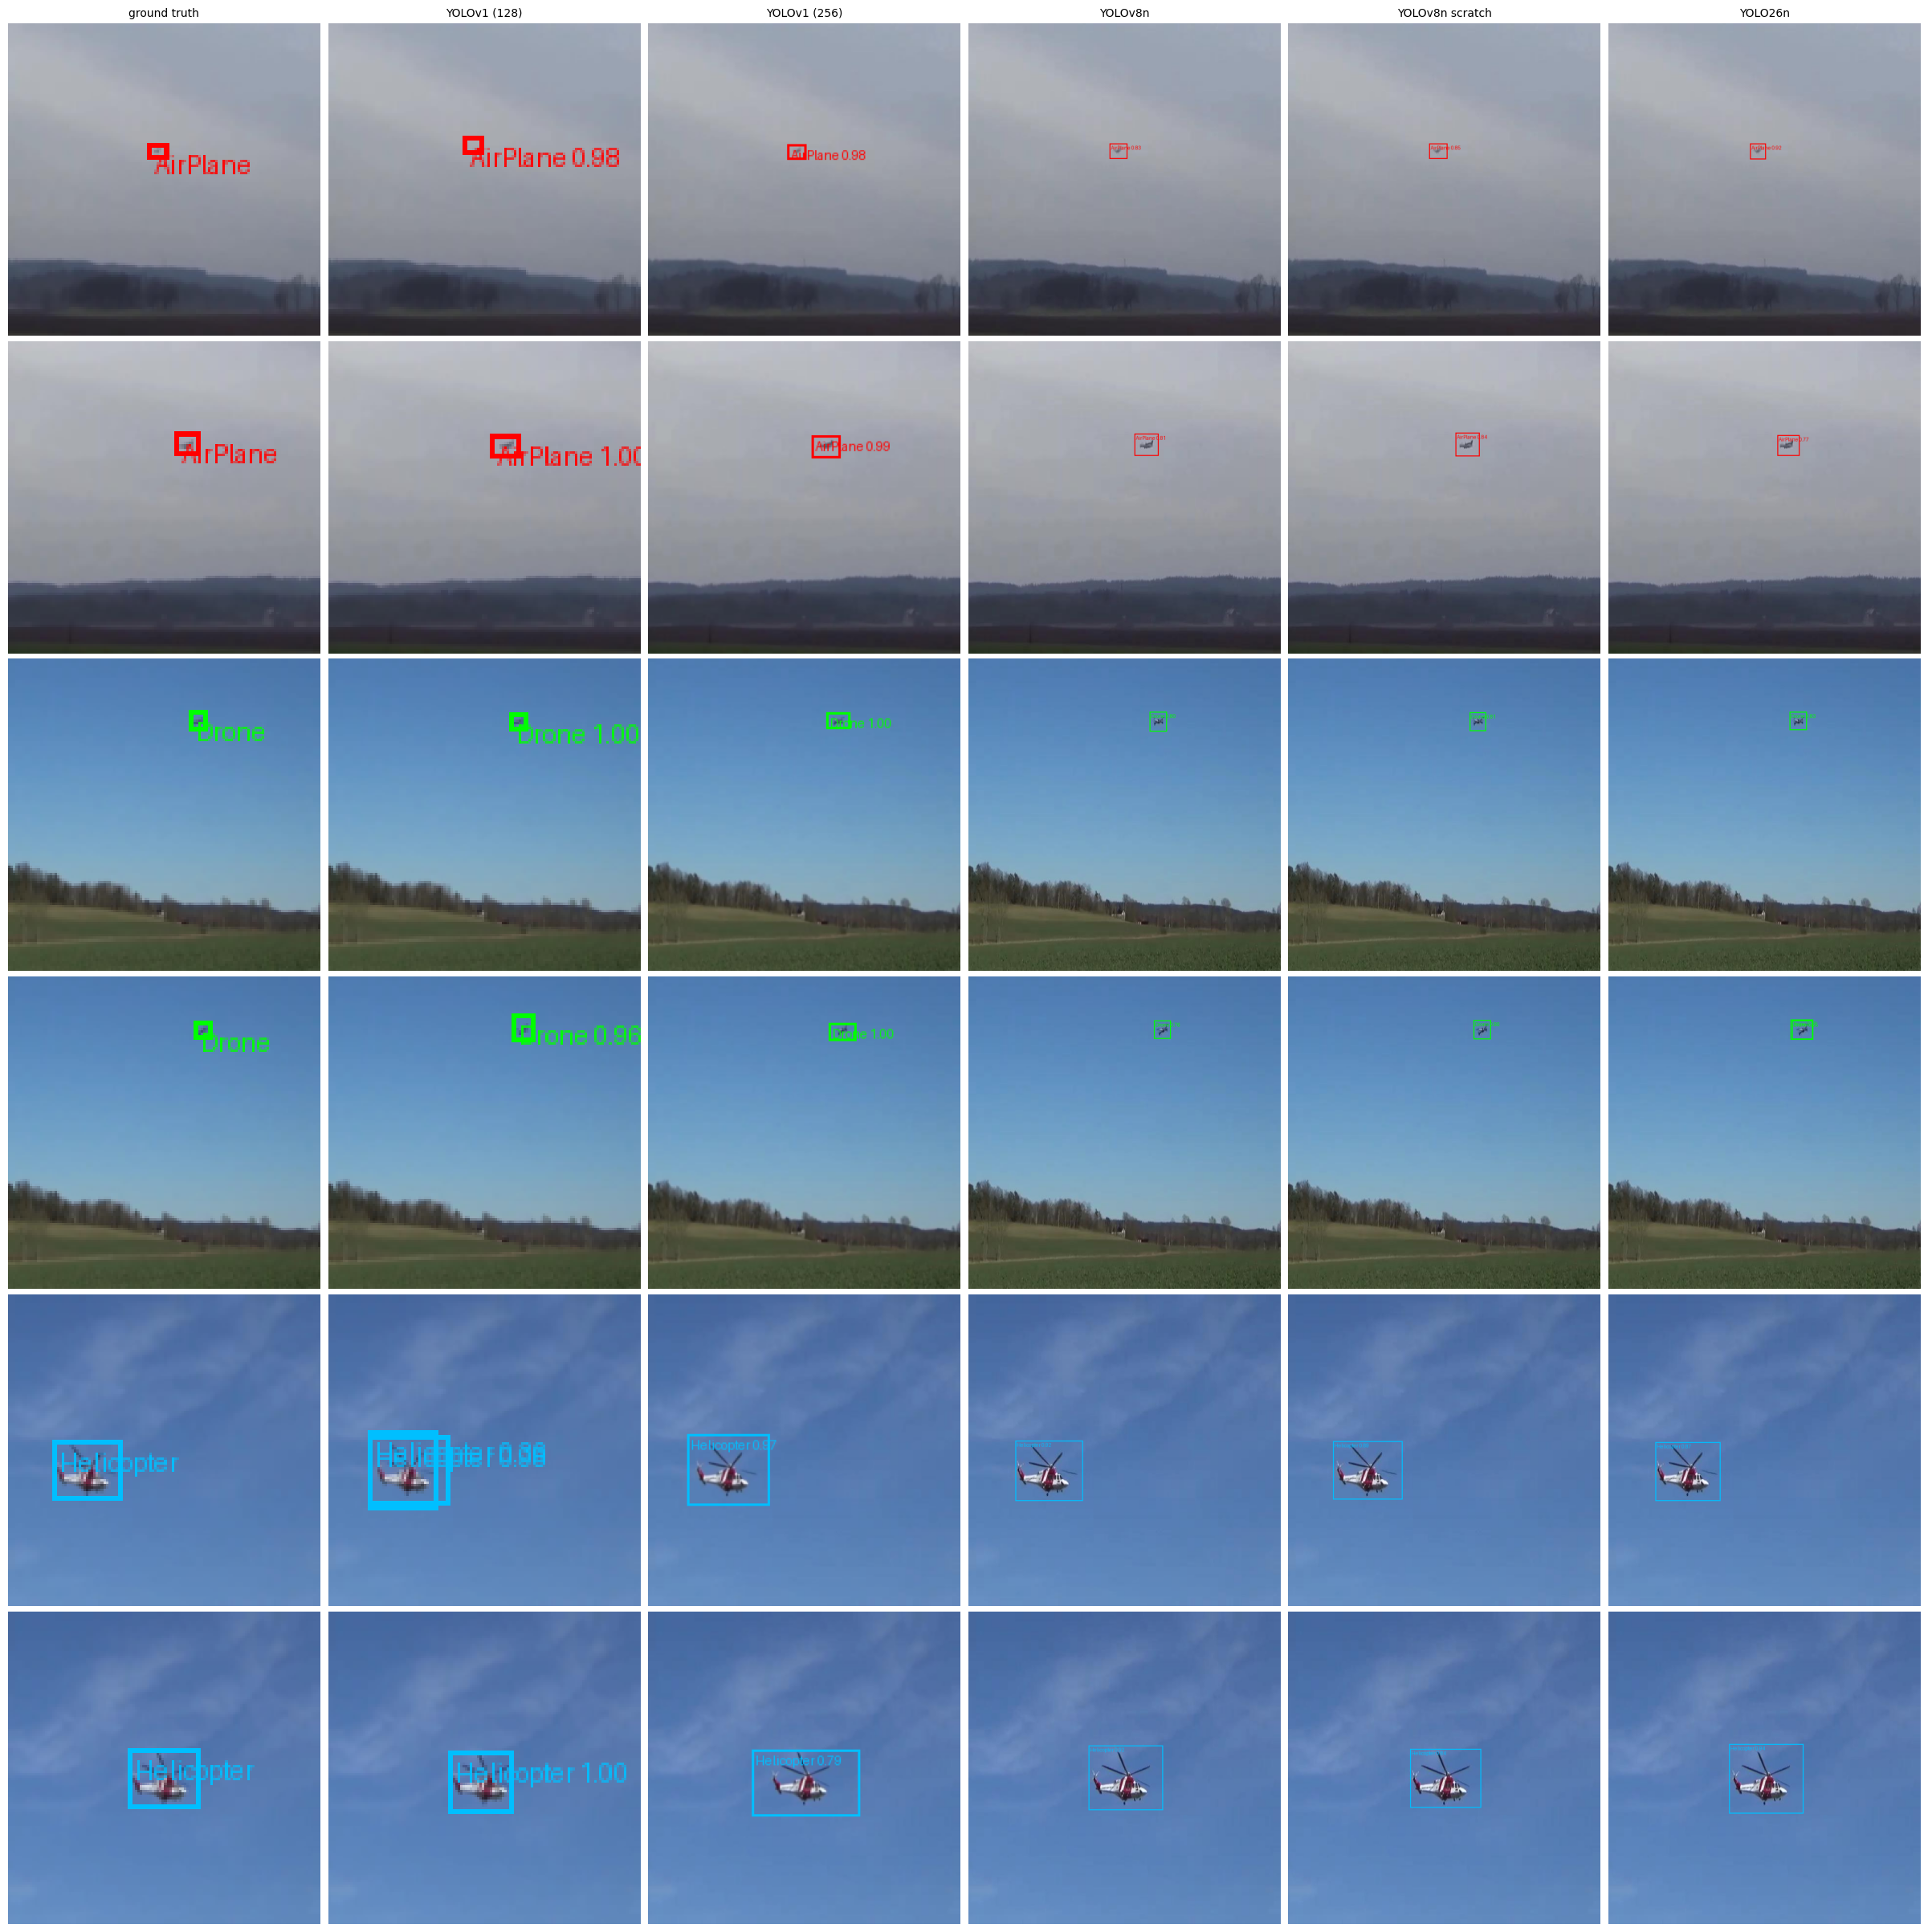

In [7]:
def predict(model, image):
    """Return {'boxes','scores','labels'} for one (3,H,W) image."""
    x = image.unsqueeze(0).to(next(model.parameters()).device)
    with torch.no_grad():
        if isinstance(model, YoloV1Baseline):
            out = model._decode_predictions(model(x), (x.shape[2], x.shape[3]))[0]
        else:
            out = model._decode_predictions(x)[0]
    return {k: v.cpu() for k, v in out.items()}


def gt_xyxy_from_targets(targets, size):
    """Normalized (cls, xc, yc, w, h) -> pixel xyxy boxes for a square image."""
    t = targets
    if len(t) == 0:
        return torch.zeros(0, 4), torch.zeros(0, dtype=torch.long)
    boxes = torch.stack([(t[:,1]-t[:,3]/2)*size, (t[:,2]-t[:,4]/2)*size,
                         (t[:,1]+t[:,3]/2)*size, (t[:,2]+t[:,4]/2)*size], dim=1)
    return boxes, t[:, 0].long()


def pick_sample_indices(dataset, per_class=2):
    """Return indices of test images with good class coverage."""
    chosen, counts = [], {c: 0 for c in range(len(CLASS_NAMES))}
    for idx in range(len(dataset)):
        tgt = dataset[idx]["targets"]
        if len(tgt) == 0:
            continue
        classes = set(int(c) for c in tgt[:, 0].tolist())
        if any(counts[c] < per_class for c in classes):
            chosen.append(idx)
            for c in classes:
                counts[c] += 1
        if all(v >= per_class for v in counts.values()):
            break
    return chosen


# Use first available model's dataset as reference for image selection.
ref_cfg = next(iter(available.values()))[0]
ref_dataset = build_datamodule_from_config(ref_cfg).test_dataset
sample_idx = pick_sample_indices(ref_dataset, per_class=2)

# Load models + per-model datasets (img_size differs between configs).
loaded = {lbl: (load_model_from_config(cfg, ckpt),
                build_datamodule_from_config(cfg).test_dataset)
          for lbl, (cfg, ckpt) in available.items()}

ncols = 1 + len(loaded)
fig, axes = plt.subplots(
    len(sample_idx), ncols,
    figsize=(4 * ncols, 4 * len(sample_idx)),
    dpi=100,
)
axes = np.atleast_2d(axes)

for r, idx in enumerate(sample_idx):
    sample = ref_dataset[idx]
    gt_boxes, gt_labels = gt_xyxy_from_targets(sample["targets"], ref_dataset.img_size)
    axes[r, 0].imshow(draw_boxes(sample["image"], gt_boxes, gt_labels, CLASS_NAMES))
    axes[r, 0].set_title("ground truth", fontsize=10) if r == 0 else None
    axes[r, 0].axis("off")

    for c, (lbl, (model, ds)) in enumerate(loaded.items(), start=1):
        img = ds[idx]["image"]
        pred = predict(model, img)
        axes[r, c].imshow(
            draw_boxes(img, pred["boxes"], pred["labels"], CLASS_NAMES, pred["scores"])
        )
        axes[r, c].set_title(lbl, fontsize=10) if r == 0 else None
        axes[r, c].axis("off")

plt.tight_layout(pad=0.5)
plt.show()

## 3. Failure cases

Scans the test set for images where at least one model makes a visible mistake:
a **missed detection** (GT box with no matching prediction) or a **class confusion**
(IoU ≥ 0.5 match but wrong label). Shows the first `N_FAILURES` such images with
GT and all model predictions side by side so the differences are easy to spot.

Found 8 failure images out of 596 scanned.


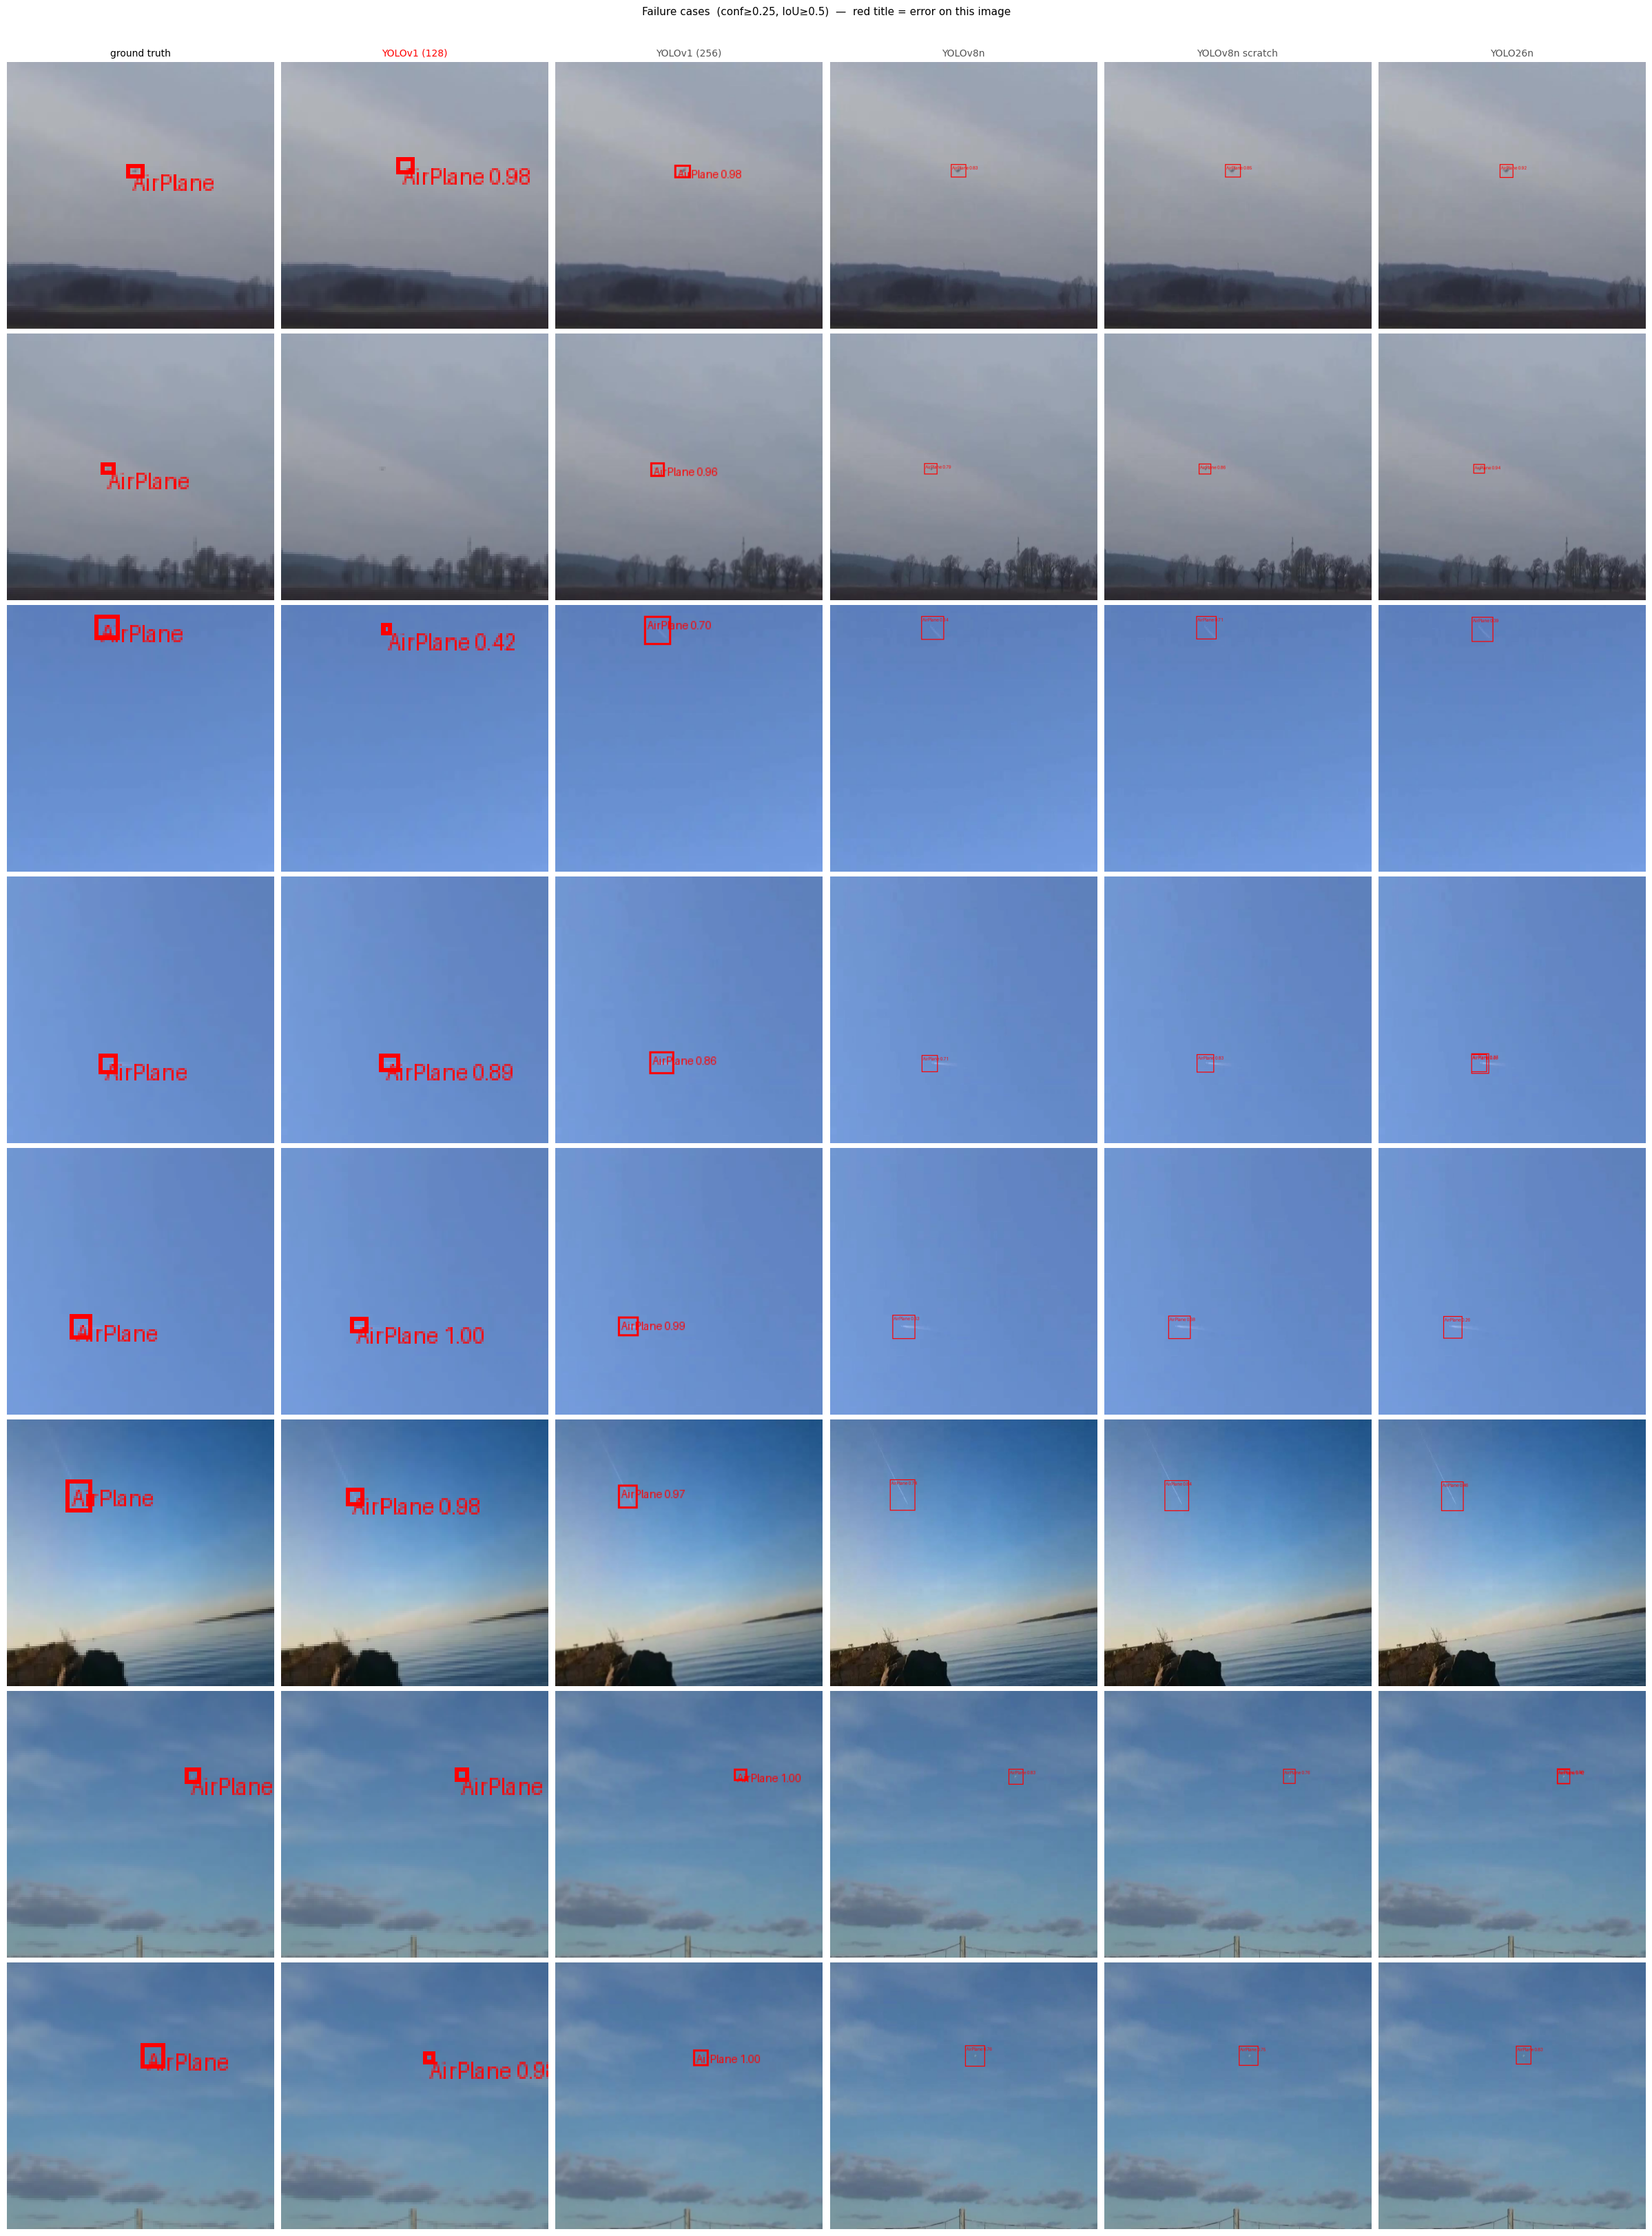

In [8]:
N_FAILURES = 8   # how many failure images to collect
CONF_THR   = 0.25
IOU_THR    = 0.50


def classify_prediction(pred, gt_boxes, gt_labels, iou_thr, conf_thr):
    """Return True if any mistake is visible: missed GT or wrong-class match."""
    keep = pred["scores"] >= conf_thr
    pb = pred["boxes"][keep]
    pl = pred["labels"][keep]

    if len(gt_boxes) == 0:
        return len(pb) > 0   # false positive on background image

    matched_gt = set()
    for pi in range(len(pb)):
        if len(gt_boxes):
            ious = box_iou(pb[pi:pi+1], gt_boxes)[0]
            best = torch.argmax(ious).item()
            if ious[best] >= iou_thr and best not in matched_gt:
                matched_gt.add(best)
                if int(pl[pi]) != int(gt_labels[best]):
                    return True  # class confusion

    if len(matched_gt) < len(gt_boxes):
        return True  # at least one missed detection

    return False


failure_idx = []
for idx in range(len(ref_dataset)):
    if len(failure_idx) >= N_FAILURES:
        break
    sample = ref_dataset[idx]
    gt_boxes, gt_labels = gt_xyxy_from_targets(sample["targets"], ref_dataset.img_size)
    if len(gt_boxes) == 0:   # skip pure background images
        continue

    is_failure = False
    for lbl, (model, ds) in loaded.items():
        img = ds[idx]["image"]
        pred = predict(model, img)
        # convert GT to this model's pixel space for fair IoU comparison
        gt_boxes_m, gt_labels_m = gt_xyxy_from_targets(sample["targets"], ds.img_size)
        if classify_prediction(pred, gt_boxes_m, gt_labels_m, IOU_THR, CONF_THR):
            is_failure = True
            break

    if is_failure:
        failure_idx.append(idx)

print(f"Found {len(failure_idx)} failure images out of {len(ref_dataset)} scanned.")

ncols = 1 + len(loaded)
fig, axes = plt.subplots(
    len(failure_idx), ncols,
    figsize=(4 * ncols, 4 * len(failure_idx)),
    dpi=100,
)
axes = np.atleast_2d(axes)

for r, idx in enumerate(failure_idx):
    sample = ref_dataset[idx]
    gt_boxes, gt_labels = gt_xyxy_from_targets(sample["targets"], ref_dataset.img_size)
    axes[r, 0].imshow(draw_boxes(sample["image"], gt_boxes, gt_labels, CLASS_NAMES))
    axes[r, 0].set_title("ground truth", fontsize=10) if r == 0 else None
    axes[r, 0].axis("off")

    for c, (lbl, (model, ds)) in enumerate(loaded.items(), start=1):
        img = ds[idx]["image"]
        pred = predict(model, img)
        gt_boxes_m, gt_labels_m = gt_xyxy_from_targets(sample["targets"], ds.img_size)
        has_mistake = classify_prediction(pred, gt_boxes_m, gt_labels_m, IOU_THR, CONF_THR)
        axes[r, c].imshow(
            draw_boxes(img, pred["boxes"], pred["labels"], CLASS_NAMES, pred["scores"])
        )
        # Red title = model made a mistake on this image, grey = correct
        col = "red" if has_mistake else "#555555"
        axes[r, c].set_title(lbl, fontsize=10, color=col) if r == 0 else None
        axes[r, c].axis("off")

plt.suptitle(
    f"Failure cases  (conf≥{CONF_THR}, IoU≥{IOU_THR})  —  red title = error on this image",
    fontsize=11, y=1.01,
)
plt.tight_layout(pad=0.5)
plt.show()

## 4. Confusion matrices

Predicted boxes are greedily matched to ground truth at IoU ≥ 0.5. Unmatched ground
truth counts as a missed detection (`background` column); unmatched predictions count
as a false positive (`background` row).

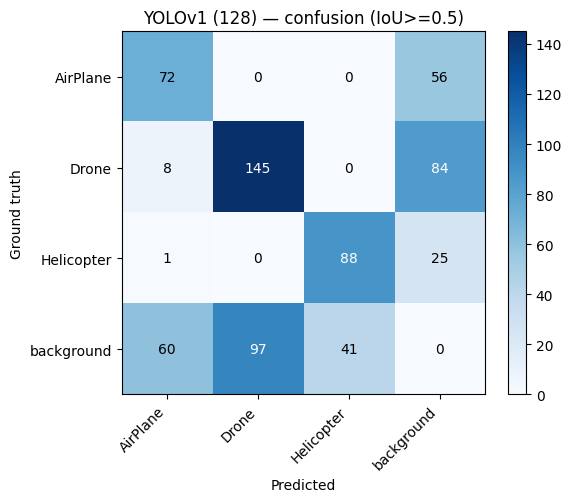

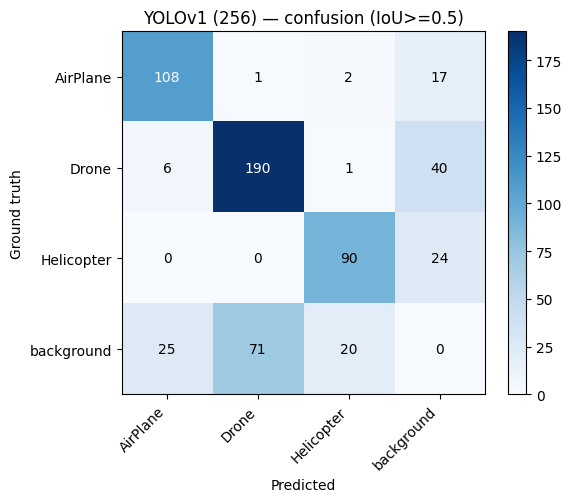

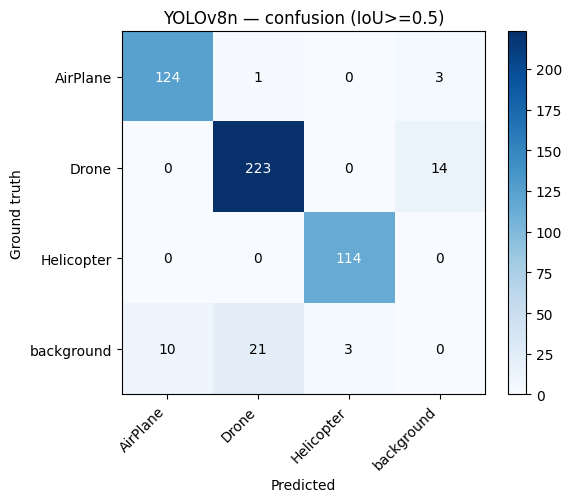

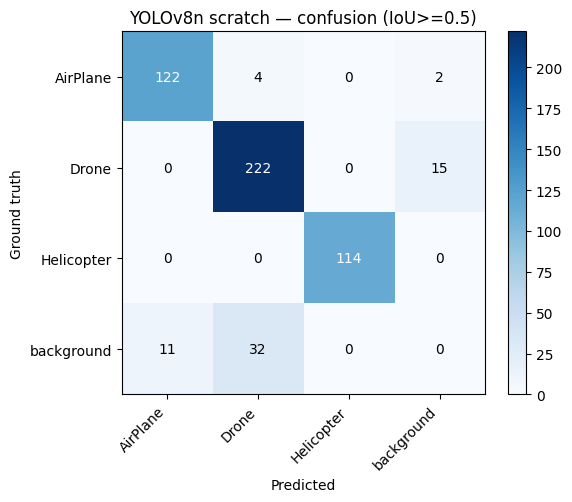

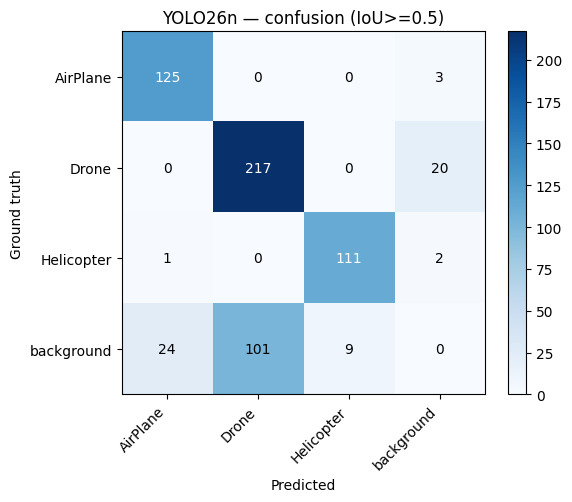

In [9]:
LABELS_CM = CLASS_NAMES + ["background"]
BG = len(CLASS_NAMES)


def confusion_for_model(model, dataset, iou_thr=0.5, conf_thr=0.25, max_images=None):
    n = len(LABELS_CM)
    cm = np.zeros((n, n), dtype=int)
    total = len(dataset) if max_images is None else min(max_images, len(dataset))
    for idx in range(total):
        sample = dataset[idx]
        gt_boxes, gt_labels = gt_xyxy_from_targets(sample["targets"], dataset.img_size)
        pred = predict(model, sample["image"])
        keep = pred["scores"] >= conf_thr
        pb, pl = pred["boxes"][keep], pred["labels"][keep]
        matched_gt = set()
        if len(pb) and len(gt_boxes):
            ious = box_iou(pb, gt_boxes)
            for pi in range(len(pb)):
                best = torch.argmax(ious[pi]).item()
                if ious[pi, best] >= iou_thr and best not in matched_gt:
                    matched_gt.add(best)
                    cm[int(gt_labels[best]), int(pl[pi])] += 1
                else:
                    cm[BG, int(pl[pi])] += 1  # false positive
        else:
            for pi in range(len(pb)):
                cm[BG, int(pl[pi])] += 1
        for gi in range(len(gt_boxes)):
            if gi not in matched_gt:
                cm[int(gt_labels[gi]), BG] += 1  # missed detection
    return cm


for lbl, (model, ds) in loaded.items():
    cm = confusion_for_model(model, ds)
    plot_confusion_matrix(cm, LABELS_CM, title=f"{lbl} — confusion (IoU>=0.5)")
    plt.show()

## 5. Ablation: isolating the factors

| comparison | isolates |
|---|---|
| YOLOv1 (128) vs YOLOv1 (256) | input resolution |
| YOLOv8n scratch vs YOLOv8n | pretrained weights (architecture fixed) |
| YOLOv1 (256) vs YOLOv8n scratch | architecture (resolution & no-pretraining controlled) |

In [10]:
ablation_rows = [r for r in ["YOLOv1 (128)", "YOLOv1 (256)", "YOLOv8n scratch", "YOLOv8n"]
                 if r in results.index]
results.loc[ablation_rows, ["mAP50", "mAP50-95"]]

,mAP50,mAP50-95
model,,
YOLOv1 (128),0.5202,0.1740
YOLOv1 (256),0.7262,0.2557
YOLOv8n scratch,0.9354,0.6635
YOLOv8n,0.9548,0.6807
